# 11 — Ilhéus x Itabuna: testes estatísticos, perguntas da reunião e transmissão estimada

**Análises do plano:** A3 (testes Ilhéus x Itabuna com Bonferroni), A5 (tempo entre diagnóstico e início do
tratamento), as perguntas levadas ao orientador e A13 (transmissão estimada nas janelas sem tratamento).

Segue o padrão do notebook 06 da pesquisa de arbovirose: teste exato de Fisher em tabelas 2x2, razão de chances
(OR) com IC 95% e correção de Bonferroni para as comparações múltiplas; Mann-Whitney para tempos.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path('..', 'src').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import mannwhitneyu
import tb_utils as tb

tb.estilo()
df = tb.carrega_base()
ii = tb.residentes_ii(df)
cidades = ['Ilhéus', 'Itabuna']
cores = tb.CORES_CIDADE
coorte = ii[ii['coorte_casos_novos']]
encerr = coorte[coorte['desfecho'] != 'Sem encerramento']
cn = ii[ii['caso_novo']]
print(len(ii), 'notificações de residentes;', len(cn), 'casos novos;', len(encerr), 'casos novos encerrados')

3251 notificações de residentes; 2643 casos novos; 2576 casos novos encerrados


## 1. Testes Ilhéus x Itabuna (A3)

Cada linha compara a proporção de um evento entre as duas cidades. OR > 1 significa que o evento é **mais
frequente em Itabuna**. "p ajustado" já tem a correção de Bonferroni.

In [2]:
comparacoes = [
    ('Cura', encerr, 'cura'),
    ('Abandono', encerr, 'abandono'),
    ('Óbito por TB', encerr, 'obito_tb'),
    ('Retratamento (recidiva ou reingresso)', ii[ii['tipo_entrada'].notna()], 'retratamento'),
    ('Forma extrapulmonar', ii.assign(extra=(ii['forma'] == 'Extrapulmonar').astype(float).where(ii['forma'].notna())), 'extra'),
    ('Confirmação laboratorial (pulmonares)', cn[cn['pulmonar']], 'confirmacao_lab'),
    ('Cultura realizada (pulmonares)', cn[cn['pulmonar']], 'cultura_realizada'),
    ('Testagem para HIV', cn, 'hiv_testado'),
    ('HIV positivo (testados)', cn[cn['hiv'].isin(['Positivo', 'Negativo'])].assign(hivpos=lambda d: (d['hiv'] == 'Positivo').astype(float)), 'hivpos'),
    ('Alcoolismo', ii, 'alcoolismo'),
    ('Drogas ilícitas', ii, 'drogas_ilicitas'),
    ('Tabagismo', ii, 'tabagismo'),
    ('Diabetes', ii, 'diabetes'),
    ('Situação de rua', ii, 'situacao_rua'),
    ('Privado de liberdade', ii, 'privado_liberdade'),
    ('Beneficiário de programa social', ii, 'beneficiario_governo'),
    ('TDO realizado (campo preenchido)', cn, 'tdo'),
    ('Início do tratamento em até 7 dias', ii.assign(ate7=(ii['dias_diag_trat'] <= 7).astype(float).where(ii['dias_diag_trat'].notna())), 'ate7'),
]
linhas = []
for nome, base, col in comparacoes:
    r = tb.compara_grupos(base, 'cidade', col, 'Itabuna', 'Ilhéus')
    linhas.append({'indicador': nome, **r})
testes = pd.DataFrame(linhas)
testes['p ajustado'] = tb.bonferroni(testes['p (Fisher)'])
testes['significativo (5%)'] = np.where(testes['p ajustado'] < 0.05, 'sim', 'não')
testes.to_csv(tb.PROCESSED / 'testes_ilheus_itabuna.csv', index=False)
testes.round(3)

,indicador,n Itabuna,% Itabuna,n Ilhéus,% Ilhéus,OR,IC95% inf,IC95% sup,p (Fisher),p ajustado,significativo (5%)
0,Cura,1471,74.507,1105,78.824,0.785,0.652,0.946,0.011,0.205,não
1,Abandono,1471,13.188,1105,11.584,1.160,0.914,1.471,0.229,1.000,não
2,Óbito por TB,1471,5.778,1105,2.262,2.649,1.684,4.167,0.000,0.000,sim
3,Retratamento (recidiva ou reingresso),1762,13.961,1489,16.320,0.832,0.686,1.009,0.062,1.000,não
4,Forma extrapulmonar,1762,15.834,1484,9.838,1.724,1.393,2.134,0.000,0.000,sim
5,Confirmação laboratorial (pulmonares),1221,64.947,1033,68.925,0.835,0.700,0.997,0.048,0.870,não
6,Cultura realizada (pulmonares),1221,16.380,1033,41.723,0.274,0.225,0.333,0.000,0.000,sim
7,Testagem para HIV,1482,70.310,1157,63.094,1.385,1.176,1.631,0.000,0.002,sim
8,HIV positivo (testados),1027,9.737,718,11.978,0.793,0.584,1.076,0.156,1.000,não
9,Alcoolismo,1488,14.583,1338,26.756,0.467,0.387,0.564,0.000,0.000,sim


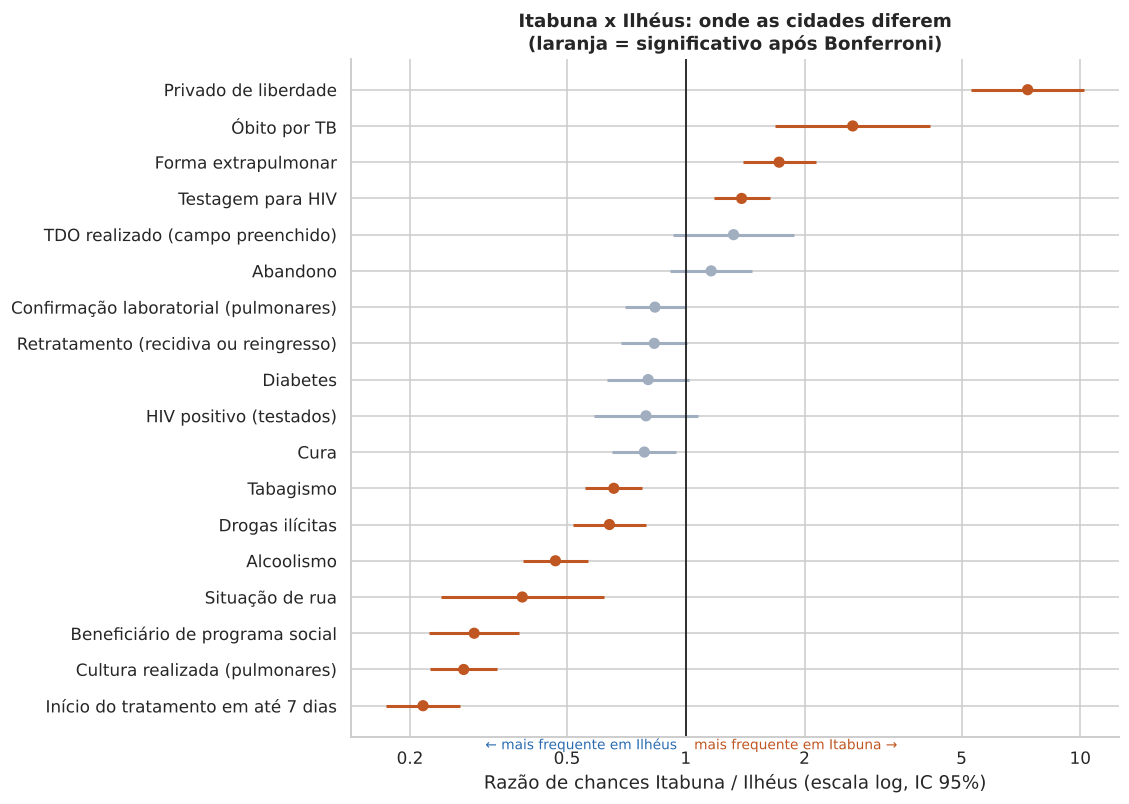

In [3]:
plot = testes.sort_values('OR')
fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(plot))
cor_pt = np.where(plot['p ajustado'] < 0.05, '#c05621', '#a0aec0')
ax.hlines(y, plot['IC95% inf'], plot['IC95% sup'], color=cor_pt, lw=2)
ax.scatter(plot['OR'], y, color=cor_pt, zorder=3, s=40)
ax.axvline(1, color='black', lw=1)
ax.set_xscale('log'); ax.set_yticks(y); ax.set_yticklabels(plot['indicador'])
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10]); ax.minorticks_off()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:g}'))
ax.set_xlabel('Razão de chances Itabuna / Ilhéus (escala log, IC 95%)')
ax.set_title('Itabuna x Ilhéus: onde as cidades diferem\n(laranja = significativo após Bonferroni)')
ax.text(1.05, -1.2, 'mais frequente em Itabuna →', fontsize=9, color='#c05621')
ax.text(0.95, -1.2, '← mais frequente em Ilhéus', fontsize=9, color='#2b6cb0', ha='right')
tb.salva_fig(fig, '11_forest_ilheus_itabuna'); plt.show()

## 2. Tempo entre diagnóstico e início do tratamento (A5 e pergunta "tempo de diagnóstico em Itabuna")

Datas impossíveis (início antes do diagnóstico ou mais de 365 dias depois) foram excluídas no notebook 09.
O gráfico agora mostra **% dos casos de cada cidade**, não contagem.

In [4]:
esp = ii[ii['dias_diag_trat'].notna()]
resumo_esp = esp.groupby('cidade')['dias_diag_trat'].describe(percentiles=[.25, .5, .75, .9]).round(1)
u = mannwhitneyu(esp.loc[esp['cidade'] == 'Ilhéus', 'dias_diag_trat'], esp.loc[esp['cidade'] == 'Itabuna', 'dias_diag_trat'])
print(f'Mann-Whitney Ilhéus x Itabuna: U = {u.statistic:.0f}, p = {tb.fmt_p(u.pvalue)}')
resumo_esp

Mann-Whitney Ilhéus x Itabuna: U = 853128, p = <0,001


,count,mean,std,min,25%,50%,75%,90%,max
cidade,,,,,,,,,
Ilhéus,1443.0,3.0,12.4,0.0,0.0,0.0,1.0,6.0,233.0
Itabuna,1703.0,23.2,55.0,0.0,0.0,1.0,15.0,75.0,365.0


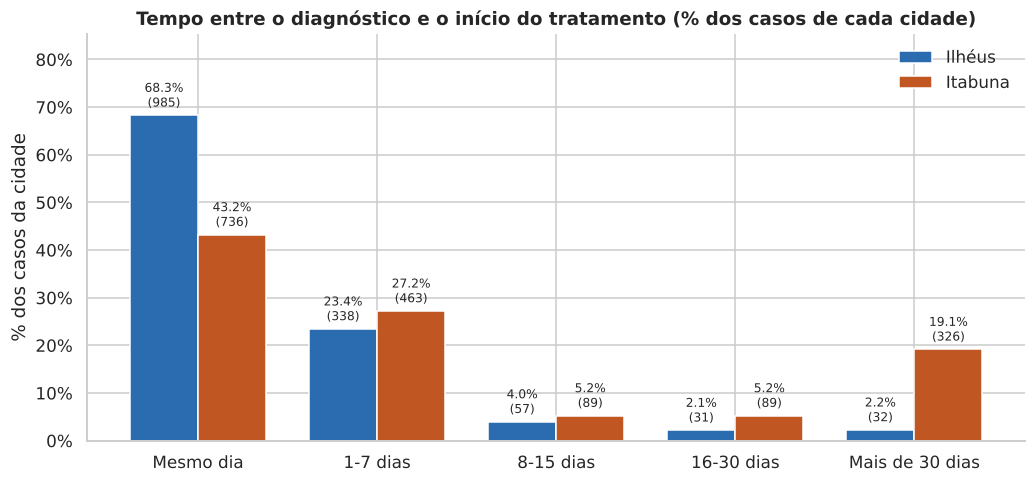

In [5]:
pct = (pd.crosstab(esp['cidade'], esp['espera_tratamento'], normalize='index') * 100)
n_abs = pd.crosstab(esp['cidade'], esp['espera_tratamento'])
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(pct.shape[1]); w = 0.38
for j, cidade in enumerate(cidades):
    barras = ax.bar(x + (j - 0.5) * w, pct.loc[cidade], w, color=cores[cidade], label=cidade)
    for xi, v, n in zip(x + (j - 0.5) * w, pct.loc[cidade], n_abs.loc[cidade]):
        ax.text(xi, v + 1, f'{v:.1f}%\n({n})', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(pct.columns)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0, pct.values.max() * 1.25)
ax.set_ylabel('% dos casos da cidade'); ax.legend(frameon=False)
ax.set_title('Tempo entre o diagnóstico e o início do tratamento (% dos casos de cada cidade)')
tb.salva_fig(fig, '11_espera_percentual'); plt.show()

In [6]:
mais30 = (esp.assign(mais30=esp['dias_diag_trat'] > 30)
          .pivot_table(index='ano_diag', columns='cidade', values='mais30', aggfunc=['sum', 'mean']))
mais30.columns = [f'{a} {c}' for a, c in mais30.columns]
mais30 = mais30.rename(columns=lambda c: c.replace('sum', 'n >30 dias').replace('mean', '% >30 dias'))
for c in [c for c in mais30.columns if c.startswith('%')]:
    mais30[c] = (mais30[c] * 100).round(1)
mais30

,n >30 dias Ilhéus,n >30 dias Itabuna,% >30 dias Ilhéus,% >30 dias Itabuna
ano_diag,,,,
2014,6,55,5.3,40.4
2015,3,65,2.3,55.1
2016,3,22,2.1,16.2
2017,2,13,1.6,7.9
2018,2,15,1.5,10.9
2019,4,16,2.5,9.5
2020,0,7,0.0,4.2
2021,3,42,2.2,24.1
2022,4,40,2.8,20.9


Para entender a espera longa em Itabuna, olhamos onde ela se concentra: tipo de entrada, forma clínica, tipo de
unidade notificadora e se a notificação foi feita só no dia do início do tratamento (o que indica que a data de
diagnóstico pode ser a do primeiro exame, e não a da confirmação).

In [7]:
it = esp[esp['cidade'] == 'Itabuna'].assign(mais30=lambda d: d['dias_diag_trat'] > 30)
it['notificou_no_inicio'] = (it['dt_notific'] - it['dt_inic_tr']).dt.days.abs() <= 1
for var in ['tipo_entrada', 'forma', 'tipo_unidade', 'baciloscopia', 'notificou_no_inicio']:
    t = it.groupby(var)['mais30'].agg(['size', 'mean']).rename(columns={'size': 'n', 'mean': '% >30 dias'})
    t['% >30 dias'] = (t['% >30 dias'] * 100).round(1)
    display(t[t['n'] >= 10].sort_values('% >30 dias', ascending=False))

,n,% >30 dias
tipo_entrada,,
Reingresso após abandono,124,48.4
Caso novo,1454,17.2
Transferência,14,14.3
Recidiva,100,12.0


,n,% >30 dias
forma,,
Extrapulmonar,275,20.7
Pulmonar,1422,18.8


,n,% >30 dias
tipo_unidade,,
Centro de saúde / UBS,1423,20.7
Hospital geral,127,13.4
Outros / não informado,137,10.9


,n,% >30 dias
baciloscopia,,
Não realizada,537,21.4
Positiva,867,18.6
Negativa,208,18.3
Não se aplica,91,13.2


,n,% >30 dias
notificou_no_inicio,,
True,1498,19.6
False,205,15.6


## 3. Perguntas da reunião

### 3.1 Alcoolismo em Ilhéus x Itabuna

A prevalência entre fichas preenchidas difere (seção 1). Como Itabuna tem mais "ignorado", testamos os dois
extremos: e se todos os ignorados fossem alcoolistas? E se nenhum fosse?

,sim,não,ignorado/vazio,prevalência entre preenchidos (%),mínimo (ignorados = não) (%),máximo (ignorados = sim) (%)
cidade,,,,,,
Ilhéus,358,980,151,26.8,24.0,34.2
Itabuna,217,1271,274,14.6,12.3,27.9


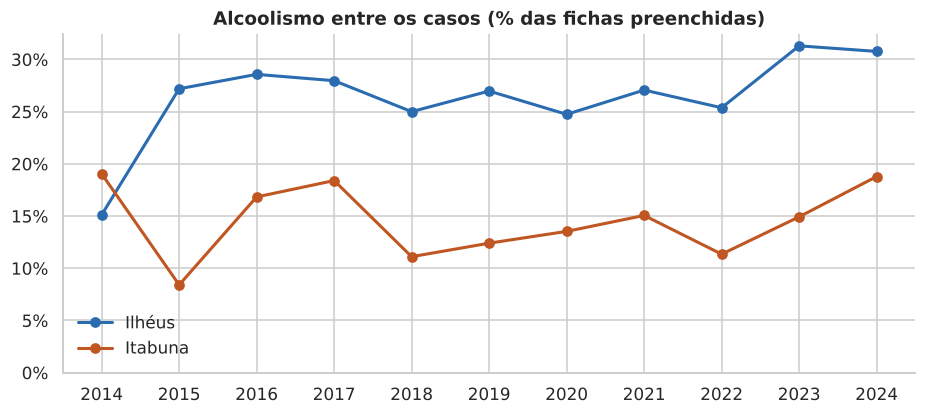

In [8]:
alc = []
for cidade in cidades:
    g = ii[ii['cidade'] == cidade]
    sim, nao, ign = int((g['alcoolismo'] == 1).sum()), int((g['alcoolismo'] == 0).sum()), int(g['alcoolismo'].isna().sum())
    alc.append({'cidade': cidade, 'sim': sim, 'não': nao, 'ignorado/vazio': ign,
                'prevalência entre preenchidos (%)': 100 * sim / (sim + nao),
                'mínimo (ignorados = não) (%)': 100 * sim / (sim + nao + ign),
                'máximo (ignorados = sim) (%)': 100 * (sim + ign) / (sim + nao + ign)})
alc = pd.DataFrame(alc).set_index('cidade')
display(alc.round(1))

alc_ano = ii.groupby(['ano_diag', 'cidade'])['alcoolismo'].mean().unstack() * 100
fig, ax = plt.subplots(figsize=(10, 4))
for cidade in cidades:
    ax.plot(alc_ano.index, alc_ano[cidade], marker='o', lw=2, color=cores[cidade], label=cidade)
ax.set_title('Alcoolismo entre os casos (% das fichas preenchidas)'); ax.set_xticks(tb.ANOS)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0); ax.legend(frameon=False)
tb.salva_fig(fig, '11_alcoolismo_ano'); plt.show()

### 3.2 Por que o TDO é baixo?

O notebook 10 mostrou que em Itabuna o campo de TDO ficou vazio de 2016 a 2020 e que o "sim" quase desaparece
depois de 2014. Aqui olhamos só Ilhéus, onde o campo está preenchido: TDO por tipo de unidade e o efeito do
TDO no abandono (sem ajuste; o ajuste está no notebook 12).

In [9]:
il = ii[ii['cidade'] == 'Ilhéus']
display(il[il['caso_novo']].groupby('tipo_unidade')['tdo'].agg(['size', 'mean']).rename(columns={'size': 'n', 'mean': '% TDO'})
        .assign(**{'% TDO': lambda d: (d['% TDO'] * 100).round(1)}).sort_values('n', ascending=False).head(6))
base_tdo = il[il['coorte_casos_novos'] & il['desfecho'].isin(['Cura', 'Abandono', 'Abandono primário'])]
r = tb.compara_grupos(base_tdo.assign(grupo=base_tdo['tdo'].map({1.0: 'Com TDO', 0.0: 'Sem TDO'})), 'grupo', 'abandono', 'Com TDO', 'Sem TDO')
pd.Series(r).round(3)

,n,% TDO
tipo_unidade,,
Centro de saúde / UBS,905,5.7
Hospital geral,142,18.7
Outros / não informado,112,7.5
Hospital especializado,1,NaN
Pronto atendimento (UPA),1,NaN


n Com TDO      56.000
% Com TDO       8.929
n Sem TDO     907.000
% Sem TDO      12.569
OR              0.682
IC95% inf       0.267
IC95% sup       1.745
p (Fisher)      0.533
dtype: float64

### 3.3 Pessoas em situação de rua em Itabuna e Ilhéus

In [10]:
rua = ii[ii['situacao_rua'] == 1]
tab_rua = pd.DataFrame({
    'casos em situação de rua': rua.groupby('cidade').size(),
    '% dos casos com campo preenchido': ii.groupby('cidade')['situacao_rua'].mean() * 100,
    'campo ignorado/vazio (%)': ii.groupby('cidade')['situacao_rua'].apply(lambda s: s.isna().mean() * 100),
    'retratamento entre eles (%)': rua.groupby('cidade')['retratamento'].mean() * 100,
    'alcoolismo entre eles (%)': rua.groupby('cidade')['alcoolismo'].mean() * 100,
}).round(1)
display(tab_rua)
desf_rua = (pd.crosstab([rua['cidade']], rua['desfecho_grupo'], normalize='index') * 100).round(1)
desf_rua

,casos em situação de rua,% dos casos com campo preenchido,campo ignorado/vazio (%),retratamento entre eles (%),alcoolismo entre eles (%)
cidade,,,,,
Ilhéus,58,4.2,7.0,55.2,76.5
Itabuna,25,1.7,14.3,32.0,47.6


desfecho_grupo,Abandono,Cura,Sem encerramento,TB-DR / falência / mudança de esquema,Transferência,Óbito por TB,Óbito por outras causas
cidade,,,,,,,
Ilhéus,50.0,25.9,8.6,1.7,8.6,1.7,3.4
Itabuna,28.0,44.0,0.0,0.0,8.0,16.0,4.0


In [11]:
lin = []
for cidade in cidades:
    b = encerr[(encerr['cidade'] == cidade) & encerr['situacao_rua'].notna()]
    b = b.assign(grupo=b['situacao_rua'].map({1.0: 'Rua', 0.0: 'Com moradia'}))
    for evento in ['cura', 'abandono']:
        lin.append({'cidade': cidade, 'evento': evento, **tb.compara_grupos(b, 'grupo', evento, 'Rua', 'Com moradia')})
pd.DataFrame(lin).round(3)

,cidade,evento,n Rua,% Rua,n Com moradia,% Com moradia,OR,IC95% inf,IC95% sup,p (Fisher)
0,Ilhéus,cura,17,17.647,1027,80.234,0.053,0.015,0.185,0.000
1,Ilhéus,abandono,17,64.706,1027,10.906,14.978,5.434,41.284,0.000
2,Itabuna,cura,16,62.500,1246,73.676,0.595,0.215,1.651,0.390
3,Itabuna,abandono,16,18.750,1246,13.884,1.431,0.404,5.074,0.479


### 3.4 Abandono por escolaridade em Itabuna

O "50% de abandono" do notebook 05 vinha de alcoolistas com escolaridade média/alta em Itabuna. Mostramos o
tamanho real desse grupo e testamos se a escolaridade muda o abandono dentro de cada grupo de alcoolismo.

In [12]:
b = encerr[encerr['desfecho'].isin(['Cura', 'Abandono', 'Abandono primário']) & encerr['escolaridade_grupo'].notna()
           & encerr['alcoolismo'].notna()].copy()
b['alcool'] = b['alcoolismo'].map({1.0: 'Alcoolista', 0.0: 'Não alcoolista'})
tab = (b.groupby(['cidade', 'alcool', 'escolaridade_grupo'])['abandono']
       .agg(n='size', abandonos='sum', taxa=lambda s: 100 * s.mean()).round(1))
display(tab)
lin = []
for cidade in cidades:
    for alcool in ['Alcoolista', 'Não alcoolista']:
        g = b[(b['cidade'] == cidade) & (b['alcool'] == alcool)]
        lin.append({'cidade': cidade, 'grupo': alcool, **tb.compara_grupos(g, 'escolaridade_grupo', 'abandono', 'Média/Alta', 'Baixa')})
pd.DataFrame(lin).round(3)

n  abandonos  taxa
cidade  alcool         escolaridade_grupo                      
Ilhéus  Alcoolista     Baixa               126       37.0  29.4
                       Média/Alta           37        6.0  16.2
        Não alcoolista Baixa               327       38.0  11.6
                       Média/Alta          214       11.0   5.1
Itabuna Alcoolista     Baixa                81       22.0  27.2
                       Média/Alta           28       14.0  50.0
        Não alcoolista Baixa               381       62.0  16.3
                       Média/Alta          400       43.0  10.8

,cidade,grupo,n Média/Alta,% Média/Alta,n Baixa,% Baixa,OR,IC95% inf,IC95% sup,p (Fisher)
0,Ilhéus,Alcoolista,37,16.216,126,29.365,0.466,0.179,1.209,0.139
1,Ilhéus,Não alcoolista,214,5.140,327,11.621,0.412,0.206,0.825,0.013
2,Itabuna,Alcoolista,28,50.000,81,27.160,2.682,1.104,6.517,0.036
3,Itabuna,Não alcoolista,400,10.750,381,16.273,0.620,0.408,0.941,0.027


## 4. Transmissão estimada nas janelas sem tratamento (A13)

**Atenção: é uma estimativa por modelo, não uma contagem.** O SINAN não registra quem infectou quem. A ideia é
dar uma ordem de grandeza ao custo do atraso.

**Parâmetros (fontes consultadas):**

- Uma pessoa com TB ativa infecta de **10 a 15 pessoas por ano** por contato próximo; infectados têm **5% a 10%**
  de risco de adoecer ao longo da vida ([OMS, Pacífico Ocidental](https://www.who.int/westernpacific/health-topics/tuberculosis)).
- Antes do diagnóstico, estudos em São José do Rio Preto (SP) encontraram mediana de **15 dias** entre sintomas e
  procura do serviço (IQR 5–45) e **15 dias** entre a primeira consulta e o diagnóstico (IQR 6–30)
  ([Ponce et al., 2016](https://scielosp.org/pdf/ress/2016.v25n3/553-562/pt); [Sasaki et al., 2015](https://scielosp.org/pdf/rbepid/2015.v18n4/809-823/pt)).
  A ficha de TB não tem data de sintomas, então esse trecho entra só como **cenário**: 30 dias (medianas somadas)
  e 75 dias (quartis superiores somados).

**Modelo:** infecções = dias sem tratamento ÷ 365 × taxa anual. Consideramos só os **bacilíferos** (pulmonares
com confirmação laboratorial), que concentram a transmissão. A taxa é aplicada de forma linear ao tempo, o que é
uma simplificação.

In [13]:
bac = ii[(ii['bacilifero'] == 1) & ii['dias_diag_trat'].notna()].copy()
print(f'Bacilíferos com data válida de início do tratamento: {len(bac)}')
TAXAS = {'baixa (10/ano)': 10, 'alta (15/ano)': 15}
PRE_DIAG = {'sem janela pré-diagnóstico': 0, 'pré-diagnóstico 30 dias': 30, 'pré-diagnóstico 75 dias': 75}

res = []
for cidade in cidades:
    g = bac[bac['cidade'] == cidade]
    dias_obs = g['dias_diag_trat'].sum()
    dias_excesso = (g['dias_diag_trat'] - 7).clip(lower=0).sum()  # o que passaria de 7 dias
    for nome_t, t in TAXAS.items():
        for nome_p, p in PRE_DIAG.items():
            inf = (dias_obs + p * len(g)) / 365 * t
            res.append({'cidade': cidade, 'taxa': nome_t, 'cenário': nome_p, 'bacilíferos': len(g),
                        'dias sem tratamento após diagnóstico': dias_obs,
                        'infecções estimadas': inf, 'casos futuros (5%)': inf * 0.05, 'casos futuros (10%)': inf * 0.10,
                        'infecções evitáveis com início em até 7 dias': dias_excesso / 365 * t})
trans = pd.DataFrame(res)
trans.to_csv(tb.PROCESSED / 'transmissao_estimada.csv', index=False)
trans[trans['cenário'] == 'sem janela pré-diagnóstico'].round(1)

Bacilíferos com data válida de início do tratamento: 1877


,cidade,taxa,cenário,bacilíferos,dias sem tratamento após diagnóstico,infecções estimadas,casos futuros (5%),casos futuros (10%),infecções evitáveis com início em até 7 dias
0,Ilhéus,baixa (10/ano),sem janela pré-diagnóstico,928,3529.0,96.7,4.8,9.7,57.3
3,Ilhéus,alta (15/ano),sem janela pré-diagnóstico,928,3529.0,145.0,7.3,14.5,85.9
6,Itabuna,baixa (10/ano),sem janela pré-diagnóstico,949,20492.0,561.4,28.1,56.1,482.8
9,Itabuna,alta (15/ano),sem janela pré-diagnóstico,949,20492.0,842.1,42.1,84.2,724.2


In [14]:
trans.pivot_table(index=['cidade', 'cenário'], columns='taxa', values='infecções estimadas').round(0)

taxa                                alta (15/ano)  baixa (10/ano)
cidade  cenário                                                  
Ilhéus  pré-diagnóstico 30 dias            1289.0           859.0
        pré-diagnóstico 75 dias            3005.0          2004.0
        sem janela pré-diagnóstico          145.0            97.0
Itabuna pré-diagnóstico 30 dias            2012.0          1341.0
        pré-diagnóstico 75 dias            3767.0          2511.0
        sem janela pré-diagnóstico          842.0           561.0

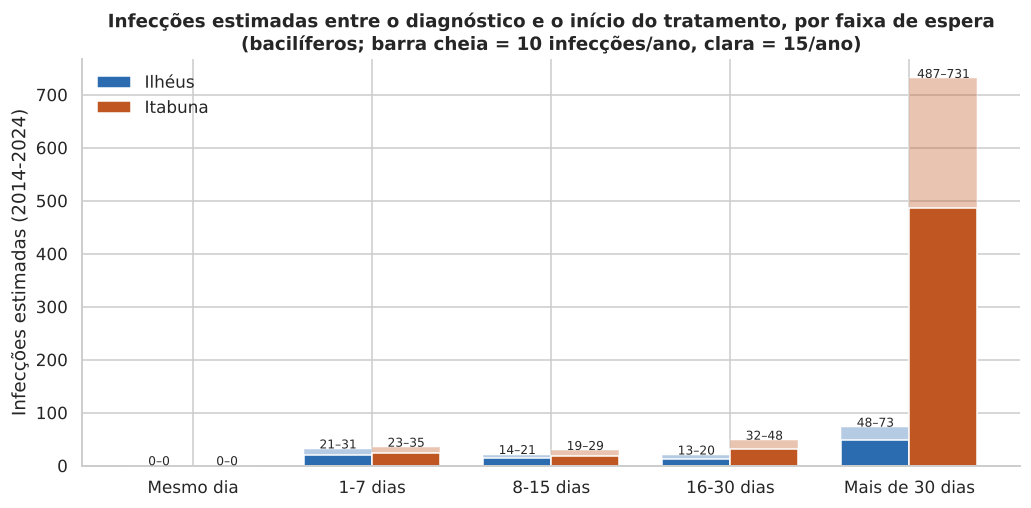

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.8))
by = bac.groupby(['cidade', 'espera_tratamento'], observed=False)['dias_diag_trat'].sum().unstack(0) / 365
low, high = by * 10, by * 15
x = np.arange(len(by)); w = 0.38
for j, cidade in enumerate(cidades):
    pos = x + (j - 0.5) * w
    ax.bar(pos, high[cidade], w, color=cores[cidade], alpha=0.35)
    ax.bar(pos, low[cidade], w, color=cores[cidade], label=cidade)
    for xi, lo_, hi_ in zip(pos, low[cidade], high[cidade]):
        ax.text(xi, hi_ + 1, f'{lo_:.0f}–{hi_:.0f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(by.index)
ax.set_ylabel('Infecções estimadas (2014-2024)'); ax.legend(frameon=False)
ax.set_title('Infecções estimadas entre o diagnóstico e o início do tratamento, por faixa de espera\n'
             '(bacilíferos; barra cheia = 10 infecções/ano, clara = 15/ano)')
tb.salva_fig(fig, '11_transmissao_por_espera'); plt.show()

**Contatos registrados (apoio):** quantos contatos cada caso pulmonar declarou e quantos foram examinados.

In [16]:
cont = cn[cn['pulmonar']].groupby('cidade').agg(
    contatos_por_caso=('n_contatos', 'mean'), mediana=('n_contatos', 'median'),
    casos_sem_nenhum_contato=('n_contatos', lambda s: 100 * (s == 0).mean()),
    contatos_identificados=('n_contatos', 'sum'), contatos_examinados=('n_contatos_examinados', 'sum'))
cont['% examinados'] = 100 * cont['contatos_examinados'] / cont['contatos_identificados']
cont.round(1)

,contatos_por_caso,mediana,casos_sem_nenhum_contato,contatos_identificados,contatos_examinados,% examinados
cidade,,,,,,
Ilhéus,3.1,3.0,15.0,3194.0,1512.0,47.3
Itabuna,2.3,2.0,34.2,2762.0,825.0,29.9


## 5. Números-chave

In [17]:
t = testes.set_index('indicador')
sig = t[t['p ajustado'] < 0.05].index.tolist()
print('Diferenças significativas após Bonferroni:', '; '.join(sig))
print(f"Espera mediana: Ilhéus {resumo_esp.loc['Ilhéus', '50%']:.0f} dias, Itabuna {resumo_esp.loc['Itabuna', '50%']:.0f} dias; "
      f"p75 Itabuna {resumo_esp.loc['Itabuna', '75%']:.0f} dias")
s = trans[trans['cenário'] == 'sem janela pré-diagnóstico'].groupby('cidade')[['infecções estimadas', 'infecções evitáveis com início em até 7 dias']].agg(['min', 'max'])
print(s.round(0))

Diferenças significativas após Bonferroni: Óbito por TB; Forma extrapulmonar; Cultura realizada (pulmonares); Testagem para HIV; Alcoolismo; Drogas ilícitas; Tabagismo; Situação de rua; Privado de liberdade; Beneficiário de programa social; Início do tratamento em até 7 dias
Espera mediana: Ilhéus 0 dias, Itabuna 1 dias; p75 Itabuna 15 dias
        infecções estimadas         \
                        min    max   
cidade                               
Ilhéus                 97.0  145.0   
Itabuna               561.0  842.0   

        infecções evitáveis com início em até 7 dias         
                                                 min    max  
cidade                                                       
Ilhéus                                          57.0   86.0  
Itabuna                                        483.0  724.0  


## Conclusões

1. **Onde as cidades diferem de fato (Fisher + Bonferroni).** Itabuna tem mais óbito por TB (5,8% x 2,3%;
   OR 2,65), mais forma extrapulmonar, mais testagem para HIV e muito mais pessoas privadas de liberdade (19,1% x
   3,1%; OR 7,4), o que aponta para o sistema prisional de Itabuna como um foco a investigar. Ilhéus tem mais
   alcoolismo, drogas, tabagismo, situação de rua e beneficiários de programa social, e faz mais cultura.
   **Cura e abandono não diferem** entre as cidades depois da correção (p ajustado 0,21 e 1,0).
2. **Espera para iniciar o tratamento.** Ilhéus começa no mesmo dia na mediana (90% em até 6 dias); Itabuna tem
   mediana de 1 dia, mas 25% esperam 15 dias ou mais e 10% esperam 75 dias ou mais (Mann-Whitney p < 0,001). A
   espera acima de 30 dias em Itabuna foi de 40% a 55% em 2014–2015, caiu para 4% a 11% em 2017–2020 e voltou a
   19% a 24% em 2021–2023. É maior em reingressos após abandono (48%) e nas UBS (21%).
3. **Alcoolismo.** A diferença (26,8% x 14,6% entre fichas preenchidas) se mantém mesmo no cenário extremo de
   tratar os ignorados como "não"; só desaparece se todos os ignorados de Itabuna fossem alcoolistas.
4. **TDO.** Em Ilhéus, onde o campo é preenchido, o TDO está mais presente nos hospitais (18,7%) que nas UBS
   (5,7%). O abandono com TDO foi 8,9% contra 12,6% sem, diferença **não significativa** (p = 0,53; só 56 com TDO).
5. **Situação de rua.** Ilhéus registra 58 casos (4,2%) e Itabuna 25 (1,7%), mas Itabuna deixa o campo vazio
   duas vezes mais (14,3% x 7,0%). Em Ilhéus, o abandono entre pessoas em situação de rua chega a 64,7% (contra
   10,9% com moradia; OR 15). Em Itabuna, o grupo é pequeno (16 casos novos encerrados) e não difere.
6. **Escolaridade em Itabuna.** O "50% de abandono" é real, mas vem de **28 alcoolistas** com escolaridade
   média/alta (14 abandonos; p = 0,036 sem correção). Entre não alcoolistas, a maior escolaridade **protege** nas
   duas cidades. O resultado de Itabuna deve ser apresentado como achado pontual de grupo pequeno.
7. **Transmissão estimada (modelo).** Considerando só o tempo entre diagnóstico e início do tratamento, os
   bacilíferos de Itabuna geraram entre 561 e 842 infecções estimadas em 11 anos, contra 97 a 145 em Ilhéus; de
   483 a 724 delas seriam evitáveis em Itabuna se todos começassem o tratamento em até 7 dias (o que daria de 24
   a 72 casos futuros de TB). Somando a janela antes do diagnóstico (cenários de 30 e 75 dias), as estimativas
   sobem para 0,9 a 3,8 mil infecções por cidade, o que mostra que o atraso antes do diagnóstico pesa mais que o
   atraso depois dele. São ordens de grandeza, com as limitações descritas na seção 4.